In [1]:
# load dataset
# correlation (top 2 features)
# make linear, poly pipeline
# mse, mae, r2 functions
# 10 - 100 training on LR with 1 feature
# best split
# LR on full
# actual(train, test), predicted LR graph
# PR on same as LR but with 2 features
# PR 3d plane
# comparisons mse, mae, r2

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, PolynomialFeatures

In [2]:
df = pd.read_csv("housing.csv")

print("Original dataset shape:", df.shape)
display(df.head())

Original dataset shape: (20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [4]:
target = "median_house_value"

cor = df.corr(numeric_only=True)[target].drop(target).abs().sort_values(ascending=False)

selected_features = cor.index[:2].tolist()
selected_features

['median_income', 'latitude']

In [5]:
def make_linear():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("linear", LinearRegression())
    ])

def make_poly():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("poly", PolynomialFeatures(degree=2)),
        ("scaler", StandardScaler()),
        ("linear", LinearRegression())
    ])

In [6]:
def calculate_mse(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    return np.mean((y_true - y_pred) ** 2)


def calculate_mae(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    return np.mean(np.abs(y_true - y_pred))


def calculate_r2(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)

    return 1 - (ss_res / ss_tot)

In [7]:
split_res = []

linear_model = make_linear()

for size in np.arange(0.1, 1.0, 0.1):
    X_train, X_test, y_train, y_test = train_test_split(
        df[[selected_features[0]]],
        df[target],
        train_size=size,
        random_state=42,
    )

    linear_model.fit(X_train, y_train)

    y_pred_train = linear_model.predict(X_train)
    y_pred_test = linear_model.predict(X_test)

    split_res.append({
        "size": size*100,
        "train_mse": calculate_mse(y_train, y_pred_train),
        "test_mse": calculate_mse(y_test, y_pred_test),
        "train_mae": calculate_mae(y_train, y_pred_train),
        "test_mae": calculate_mae(y_test, y_pred_test),
        "train_r2": calculate_r2(y_train, y_pred_train),
        "test_r2": calculate_r2(y_test, y_pred_test),
    })

split_res_df = pd.DataFrame(split_res)

display(split_res_df)

,size,train_mse,test_mse,train_mae,test_mae,train_r2,test_r2
0,10.0,7.292737e+09,6.980323e+09,63760.537421,62558.311435,0.461856,0.474740
1,20.0,7.208898e+09,6.963085e+09,63286.425368,62608.108694,0.464416,0.475647
2,30.0,6.971473e+09,7.029075e+09,62487.286815,62493.768378,0.478605,0.471158
3,40.0,6.995504e+09,7.022029e+09,62468.320103,62623.681668,0.477767,0.470519
4,50.0,7.029662e+09,6.993265e+09,62585.974016,62553.822681,0.474462,0.472393
5,60.0,6.961719e+09,7.086544e+09,62275.977094,62869.644497,0.475266,0.470642
6,70.0,7.051367e+09,6.917980e+09,62703.317285,62315.592938,0.473659,0.472932
7,80.0,6.991447e+09,7.091158e+09,62495.076557,62990.865301,0.476993,0.458859
8,90.0,6.978790e+09,7.306836e+09,62452.259276,63720.794458,0.475800,0.452101


In [8]:
selected_split = split_res_df.loc[split_res_df["test_mse"].idxmin()]
selected_split

size         7.000000e+01
train_mse    7.051367e+09
test_mse     6.917980e+09
train_mae    6.270332e+04
test_mae     6.231559e+04
train_r2     4.736592e-01
test_r2      4.729319e-01
Name: 6, dtype: float64

In [9]:
print(linear_model.named_steps)

{'imputer': SimpleImputer(strategy='median'), 'scaler': StandardScaler(), 'linear': LinearRegression()}


In [ ]:
best_train_size = selected_split["size"] / 100   # fraction, e.g. 0.3

X_train, X_test, y_train, y_test = train_test_split(
    df[[selected_features[0]]],
    df["median_house_value"],
    train_size=best_train_size,
    random_state=42
)
linear_model.fit(X_train, y_train)

linear_train_pred = linear_model.predict(X_train)
linear_pred = linear_model.predict(X_test)

linear_train_mse = calculate_mse(y_train, linear_train_pred)
linear_train_mae = calculate_mae(y_train, linear_train_pred)
linear_train_r2 = calculate_r2(y_train, linear_train_pred)

linear_mse = calculate_mse(y_test, linear_pred)
linear_mae = calculate_mae(y_test, linear_pred)
linear_r2 = calculate_r2(y_test, linear_pred)

regressor = linear_model.named_steps["linear"]
print(regressor.coef_[0])
print(regressor.intercept_)

79662.15775532361
206924.8693154288


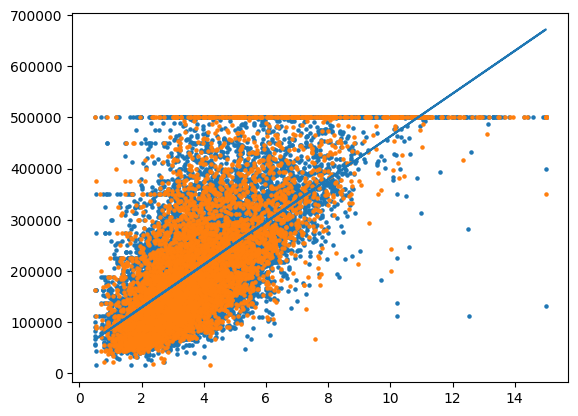

In [11]:
plt.scatter(X_train[selected_features[0]], y_train, s=5)
plt.scatter(X_test[selected_features[0]], y_test, s=5)
plt.plot(X_test[selected_features[0]], linear_pred)

plt.show()

In [12]:
polynomial_model = make_poly()

X_poly_train = df.loc[X_train.index, selected_features]
X_poly_test = df.loc[X_test.index, selected_features]

y_poly_train = df.loc[X_train.index, "median_house_value"]
y_poly_test = df.loc[X_test.index, "median_house_value"]

polynomial_model.fit(X_poly_train, y_poly_train)

poly_train_pred = polynomial_model.predict(X_poly_train)
poly_pred = polynomial_model.predict(X_poly_test)

poly_train_mse = calculate_mse(y_poly_train, poly_train_pred)
poly_train_mae = calculate_mae(y_poly_train, poly_train_pred)
poly_train_r2 = calculate_r2(y_poly_train, poly_train_pred)

poly_mse = calculate_mse(y_poly_test, poly_pred)
poly_mae = calculate_mae(y_poly_test, poly_pred)
poly_r2 = calculate_r2(y_poly_test, poly_pred)

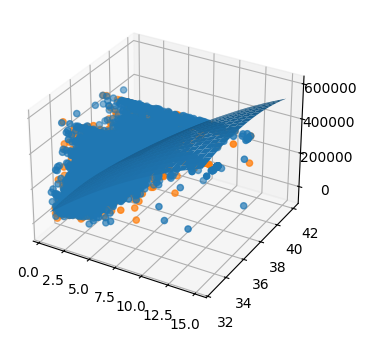

In [13]:
model_plane = polynomial_model   # surface of the fitted degree-2 model

ax = plt.figure(figsize=(18, 4)).add_subplot(projection="3d")

ax.scatter(X_poly_train[selected_features[0]], X_poly_train[selected_features[1]], y_poly_train)
ax.scatter(X_poly_test[selected_features[0]], X_poly_test[selected_features[1]], y_poly_test)

x1 = np.linspace(df[selected_features[0]].min(), df[selected_features[0]].max(), 20)
x2 = np.linspace(df[selected_features[1]].min(), df[selected_features[1]].max(), 20)
X1, X2 = np.meshgrid(x1, x2)

grid = pd.DataFrame({selected_features[0]: X1.ravel(), selected_features[1]: X2.ravel()})
Z = model_plane.predict(grid).reshape(X1.shape)

ax.plot_surface(X1, X2, Z)

plt.show()

,Simple Linear Regression,Polynomial Regression
MSE (% of variance),52.71,50.73
MAE (% of mean),30.15,29.44
R² (%),47.29,49.27


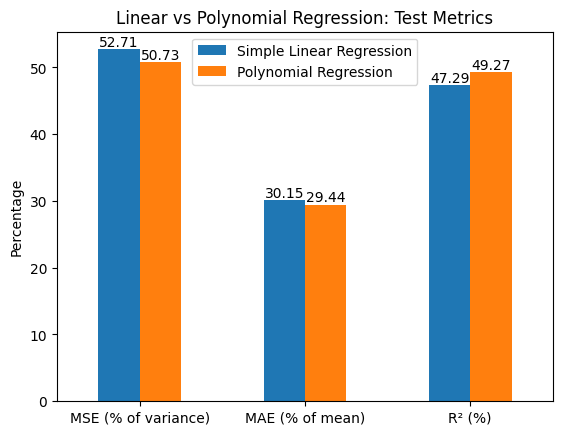

In [14]:
comparison_percent = pd.DataFrame({
    "Simple Linear Regression": [
        linear_mse / np.var(y_test) * 100,
        linear_mae / np.mean(y_test) * 100,
        linear_r2 * 100
    ],
    "Polynomial Regression": [
        poly_mse / np.var(y_test) * 100,
        poly_mae / np.mean(y_test) * 100,
        poly_r2 * 100
    ]
}, index=["MSE (% of variance)", "MAE (% of mean)", "R² (%)"])

display(comparison_percent.round(2))

ax = comparison_percent.plot(kind="bar", rot=0)
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.2f")

plt.ylabel("Percentage")
plt.title("Linear vs Polynomial Regression: Test Metrics")
plt.show()

In [ ]:
# predict house value from user input (press Enter to use the median value)

user = {}
for col in selected_features:
    val = input(f"{col} [{df[col].median():.2f}]: ").strip()
    user[col] = float(val) if val else df[col].median()
user_df = pd.DataFrame([user])

linear_value = linear_model.predict(user_df[[selected_features[0]]])[0]
poly_value = polynomial_model.predict(user_df)[0]

print("\nInput:", user)
print(f"Linear Regression     ({selected_features[0]}) -> ${linear_value:,.0f}")
print(f"Polynomial Regression ({', '.join(selected_features)}) -> ${poly_value:,.0f}")